## EDA 
The dataset was downloaded from Kaggle, and only the New York (NY) portion was used due to memory constraints, ensuring the data could be efficiently processed on a local machine.

In [1]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import warnings
import calendar
# set display columns to max so that we can view all columns
pd.set_option('display.max_columns', None)
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv("data/raw/US_Accidents_March23_NY.csv")

In [3]:
data_nj = data.copy()

In [4]:
data.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-194257,Source2,3,2016-11-30 16:25:41,2016-11-30 17:10:30,41.139324,-74.169876,NaN,NaN,0.01,Right lane blocked due to accident on I-87 Sou...,Route 17,Sloatsburg,Rockland,NY,10974,US,US/Eastern,KCDW,2016-11-30 16:53:00,53.1,NaN,93.0,29.81,1.0,East,11.5,0.00,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-194258,Source2,3,2016-11-30 15:40:06,2016-11-30 17:09:40,41.118748,-74.159744,NaN,NaN,2.53,Accident on I-87 Southbound between Exit 14B C...,I-287 S,Suffern,Rockland,NY,10901,US,US/Eastern,KCDW,2016-11-30 15:53:00,53.1,NaN,93.0,29.83,1.0,ENE,8.1,0.02,Overcast,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-194259,Source2,3,2016-11-30 15:26:18,2016-11-30 16:56:02,41.014034,-73.717239,NaN,NaN,1.17,Accident on I-287 Cross Westchester Expy Eastb...,Hutchinson River Pkwy S,White Plains,Westchester,NY,10605,US,US/Eastern,KHPN,2016-11-30 15:56:00,52.0,NaN,93.0,29.81,2.0,East,17.3,0.15,Light Rain,False,False,False,False,True,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-194260,Source2,3,2016-11-30 16:14:11,2016-11-30 16:59:00,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-194261,Source2,3,2016-11-30 16:17:57,2016-11-30 17:02:44,41.390369,-73.597969,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,I-84 E,Brewster,Putnam,NY,10509,US,US/Eastern,KDXR,2016-11-30 15:53:00,52.0,NaN,89.0,29.86,3.0,East,10.4,0.05,Rain,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [5]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight'],
      dtype='object')

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     347960 non-null  object 
 1   Source                 347960 non-null  object 
 2   Severity               347960 non-null  int64  
 3   Start_Time             347960 non-null  object 
 4   End_Time               347960 non-null  object 
 5   Start_Lat              347960 non-null  float64
 6   Start_Lng              347960 non-null  float64
 7   End_Lat                194902 non-null  float64
 8   End_Lng                194902 non-null  float64
 9   Distance(mi)           347960 non-null  float64
 10  Description            347959 non-null  object 
 11  Street                 347312 non-null  object 
 12  City                   347932 non-null  object 
 13  County                 347960 non-null  object 
 14  State                  347960 non-nu

In [7]:
data.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
Severity,347960.0,2.259550,0.511014,1.000000,2.000000,2.000000,2.000000,4.000000
Start_Lat,347960.0,41.560975,0.999105,40.503048,40.758131,40.976681,42.743330,45.001892
Start_Lng,347960.0,-74.556611,1.574805,-79.761920,-74.088270,-73.894638,-73.760542,-71.861031
End_Lat,194902.0,41.536836,0.999496,40.505200,40.750500,40.918790,42.714843,44.997320
End_Lng,194902.0,-74.526908,1.528085,-79.761981,-74.076729,-73.903030,-73.769342,-71.943680
Distance(mi),347960.0,0.751562,2.124309,0.000000,0.000000,0.069000,0.713000,112.903000
Temperature(F),345892.0,54.840956,19.336263,-77.800000,39.000000,56.000000,71.000000,172.000000
Wind_Chill(F),276306.0,49.544803,23.010782,-39.000000,31.000000,52.000000,69.000000,172.000000
Humidity(%),345769.0,65.880507,20.201403,1.000000,50.000000,66.000000,84.000000,100.000000
Pressure(in),344976.0,29.813697,0.382717,19.750000,29.600000,29.870000,30.070000,30.890000


## Exploratory Data Analysis

In [8]:
# Convert datetime columns to proper format
data['Start_Time'] = pd.to_datetime(data['Start_Time'], format='mixed', errors='coerce') 
data['End_Time'] = pd.to_datetime(data['End_Time'], format='mixed', errors='coerce')

In [9]:
#missing value

data.isnull().sum().sort_values(ascending=False)

End_Lat                  153058
End_Lng                  153058
Precipitation(in)         86511
Wind_Chill(F)             71654
Wind_Speed(mph)           17879
Wind_Direction             4477
Visibility(mi)             3081
Pressure(in)               2984
Weather_Condition          2726
Humidity(%)                2191
Temperature(F)             2068
Weather_Timestamp          1459
Nautical_Twilight           710
Civil_Twilight              710
Sunrise_Sunset              710
Astronomical_Twilight       710
Street                      648
Airport_Code                347
City                         28
Description                   1
Traffic_Signal                0
Railway                       0
Roundabout                    0
Station                       0
Stop                          0
Traffic_Calming               0
Country                       0
Junction                      0
Turning_Loop                  0
End_Time                      0
Start_Time                    0
Severity

### Univariate analysis:

Distribution of severity levels - Countplot of severity levels.
Accident counts by hour, day, month - Histograms of accidents.
Weather condition frequencies - Bar chart of top 10 weather conditions.
Numeric features: Histograms- boxplots and helps to identify Outliers as well.



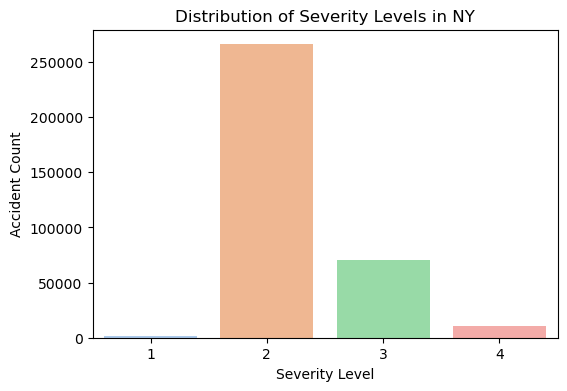


Severity counts:


Severity
2    265902
3     70062
4     10749
1      1247
Name: count, dtype: int64

In [10]:
# Distribution of severity levels - Countplot of severity levels.
plt.figure(figsize=(6,4))
sns.countplot(x='Severity', data=data, palette='pastel')
plt.title('Distribution of Severity Levels in NY')
plt.xlabel('Severity Level')
plt.ylabel('Accident Count')
plt.show()
print('\nSeverity counts:')
display(data['Severity'].value_counts())

* The dataset is highly imbalanced, dominated by Severity Level 2 incidents.
* Most accidents in NY are of moderate severity
* Since the data is imbalanced, resampling techniques (e.g SMOTE, Threshold tuning ) may be needed for predictive modeling.
* Severity 3 and 4 might correspond to more serious conditions but occur less frequently.

Consolidated severity counts:
Severity_Class
Minor         1247
Moderate    265902
Major        80811
Name: count, dtype: int32


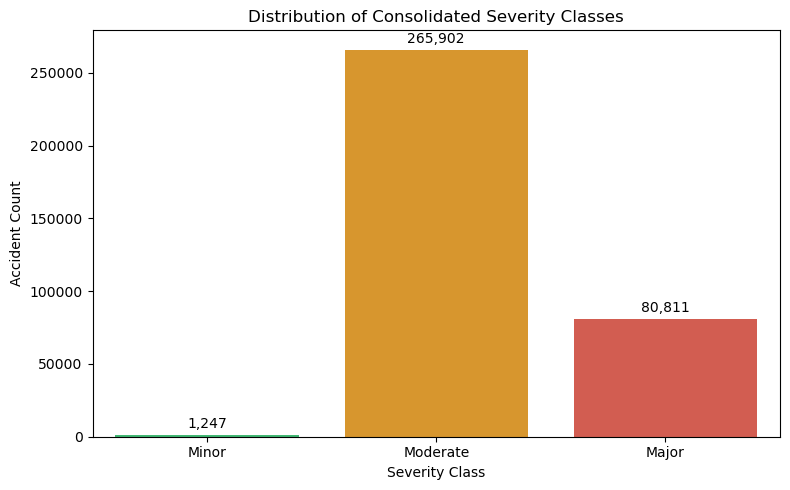

In [11]:
# Consolidate severity, count classes, and plot a color-coded bar chart
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Minor: Small damage or no injury.

# Moderate: Injuries that need medical attention but are not life-threatening.

# Major: Fatal or severe injuries, or major property damage.

# Map original severity to consolidated classes
severity_map = {1: 'Minor', 2: 'Moderate', 3: 'Major', 4: 'Major'}
data['Severity_Class'] = data['Severity'].map(severity_map)

# Count occurrences
counts = data['Severity_Class'].value_counts().reindex(['Minor', 'Moderate', 'Major']).fillna(0).astype(int)

# Print counts (useful in notebook)
print("Consolidated severity counts:")
print(counts)

# Plot
plt.figure(figsize=(8, 5))
palette = {'Minor':'#2ecc71', 'Moderate':'#f39c12', 'Major':'#e74c3c'}  # green, orange, red
sns.barplot(x=counts.index, y=counts.values, palette=[palette[c] for c in counts.index])

# Labels and aesthetics
plt.title('Distribution of Consolidated Severity Classes')
plt.xlabel('Severity Class')
plt.ylabel('Accident Count')
for i, v in enumerate(counts.values):
    plt.text(i, v + counts.values.max()*0.01, f"{v:,}", ha='center', va='bottom')
plt.tight_layout()

* merging severity 3 and 4 into serious to reduce imbalance 

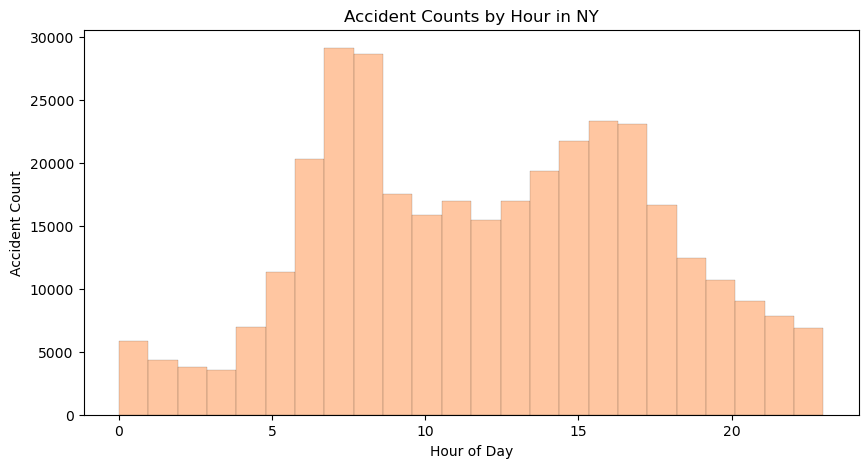

In [12]:
# 2 Accident Counts by Hour, Day, Month
# Hour
colors = sns.color_palette('pastel')
plt.figure(figsize=(10, 5))
sns.histplot(data['Start_Time'].dt.hour, bins=24, kde=False, color=colors[1], linewidth=.1)
plt.title('Accident Counts by Hour in NY')
plt.xlabel('Hour of Day')
plt.ylabel('Accident Count')
plt.show()

* A strong morning peak at 7 to 8 AM and an afternoon peak around 3 to 5 PM.
* Very low counts overnight
* Peaks approach the chart's upper range, indicating a large share of daily accidents occur during commute hours.

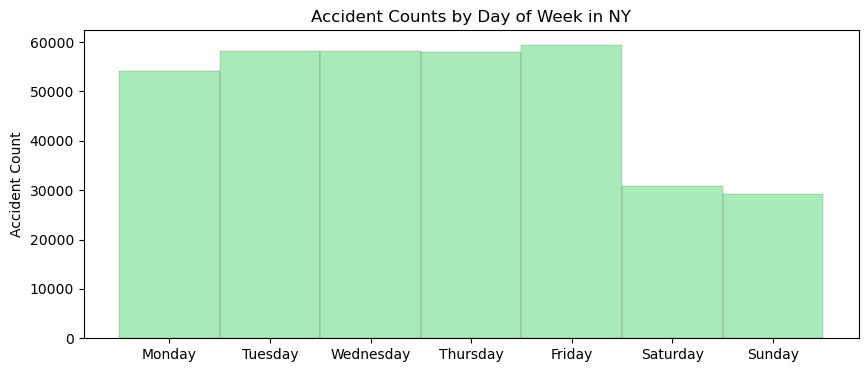

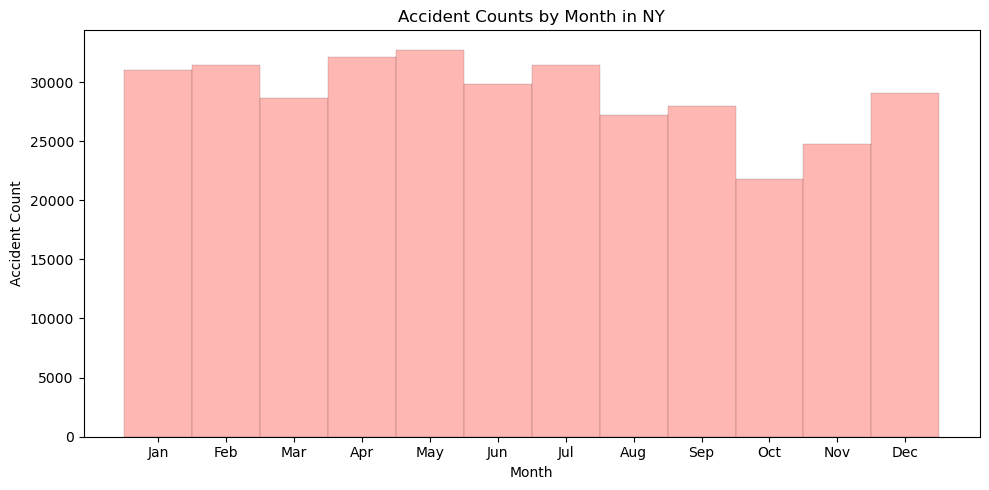

In [13]:
import calendar
# Day of Week
plt.figure(figsize=(10, 4))
data['Weekday'] = data['Start_Time'].dt.dayofweek.map(lambda x: calendar.day_name[x])
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
# Define weekday order
weekday_order = list(calendar.day_name)
data['Weekday'] = pd.Categorical(data['Weekday'], categories=order, ordered=True)

sns.histplot(data,x= "Weekday", bins=7, kde=False, color=colors[2], linewidth=.1)
plt.title('Accident Counts by Day of Week in NY')
plt.xlabel('')
plt.ylabel('Accident Count')
plt.show()


# Month
# Step 1: Create a new column with month names
data['Month_Name'] = data['Start_Time'].dt.month.map(lambda x: calendar.month_abbr[x])

# Step 2: Sort month names in calendar order
month_order = calendar.month_abbr[1:]  # ['Jan', 'Feb', ..., 'Dec']

# Step 3: Plot histogram using categorical month names
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='Month_Name', bins=len(month_order), discrete=True,
             color=colors[3], linewidth=0.1)

# Step 4: Customize labels
plt.title('Accident Counts by Month in NY')
plt.xlabel('Month')
plt.ylabel('Accident Count')
plt.xticks(ticks=range(len(month_order)), labels=month_order)

plt.tight_layout()
plt.show()

<u> Accident counts by day of week </u>

* Weekdays (Monday-Friday) show consistently high accident counts; Friday peaks slightly above other weekdays.
* Saturday and Sunday have substantially fewer accidents, indicating much lower exposure or travel volume.
* Work-commute and weekday activity drive most incidents; Friday’s rise may reflect higher traffic, end-of-week travel or different driving behaviors.

<u>Accident counts by month</u>

* Counts vary across the year with peaks in May and December and lows in October–November.
* Spring increase (May) could be higher travel and clearer weather encouraging more trips; December peak may reflect holiday travel, worse lighting, and adverse weather in parts of the state.

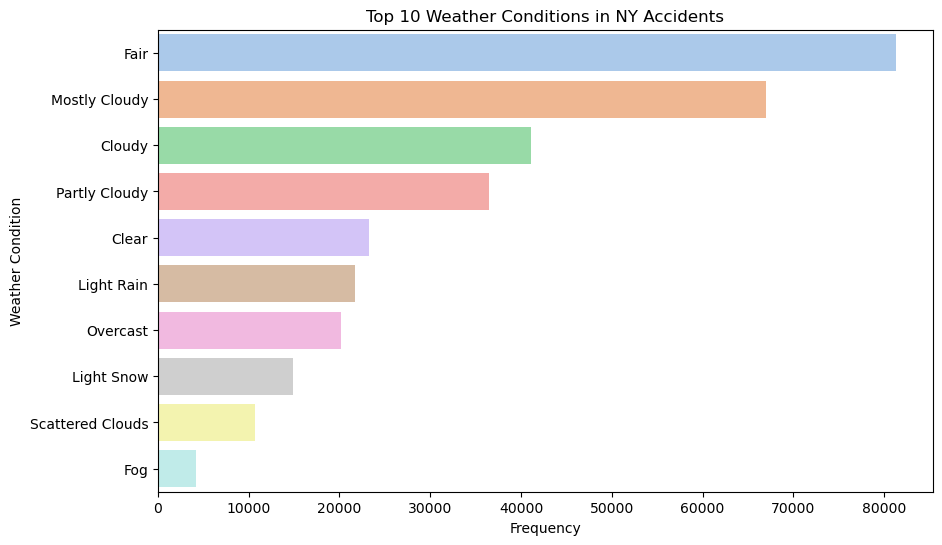

In [14]:
# 3 Weather Condition Frequencies (Top 10)
top_weather = data['Weather_Condition'].value_counts().nlargest(10)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_weather.values, y=top_weather.index, palette='pastel')
plt.title('Top 10 Weather Conditions in NY Accidents')
plt.xlabel('Frequency')
plt.ylabel('Weather Condition')
plt.show()

* Most accidents occur in Fair / Mostly Cloudy / Cloudy conditions (clear-weather majority), not just during rain or snow.
* high counts in fair weather likely reflect much higher driving exposure; conditional crash risk per mile may still be higher in precipitation or fog.

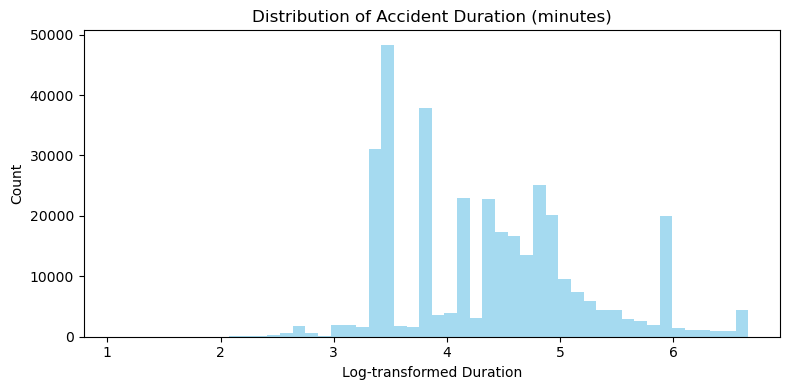

In [15]:
# Histogram of accident duration (log-transformed to reduce skew)

# Ensure datetime format
data['Start_Time'] = pd.to_datetime(data['Start_Time'])
data['End_Time'] = pd.to_datetime(data['End_Time'])

# Calculate duration in minutes
data['Duration'] = (data['End_Time'] - data['Start_Time']).dt.total_seconds() / 60

# Cap extreme outliers at 99th percentile
duration_cap = data['Duration'].quantile(0.99)
data['Duration'] = np.where(data['Duration'] > duration_cap, duration_cap, data['Duration'])

# Apply log transformation to reduce skew
data['Duration'] = np.log1p(data['Duration'])



plt.figure(figsize=(8, 4))
sns.histplot(data['Duration'], bins=50, color='skyblue', edgecolor=None)
plt.title('Distribution of Accident Duration (minutes)')
plt.xlabel('Log-transformed Duration')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

#  duration can be highly skewed due to rare, long incidents.
# Duration is a strong candidate for predicting severity, especially when combined with location, time, and weather.
# Right-Skewed Distribution:

* The log-transformed distribution is right-skewed, showing that most accidents have shorter durations.
* A large concentration occurs between log(3) and log(4) (roughly 20–60 minutes in actual duration).
* The log transformation effectively normalizes the spread, making the distribution closer to normal and easier to model.

#### Bivariate analysis:
 * Scatter plot of accidents using latitude and longitude.
 * Severity vs weather conditions - Grouped bar chart of severity across weather conditions
 * Severity vs time of day/day of week - Boxplot of severity by hour of day / Countplot of severity by day of week
 * Severity vs road infrastructure features.

In [34]:
import plotly.express as px

# Sample for performance
sample_data = data[['Start_Lat', 'Start_Lng', 'Severity','City']].dropna().sample(5000, random_state=42)

fig = px.scatter_mapbox(sample_data,
                        lat='Start_Lat', lon='Start_Lng',
                        color='Severity',
                        color_continuous_scale='RdYlGn_r',
                        zoom=7,
                        mapbox_style='carto-positron',
                        title='Accident Locations in NY (by Severity)')

fig.show()

* Accidents cluster heavily in urbanized corridors (northern NY, NYC metro, major highways and bridge/tunnel approaches) indicating high exposure and complex traffic interactions.

In [17]:
import folium
from folium.plugins import MarkerCluster

# Sample subset for performance
sample_data = data[['Start_Lat', 'Start_Lng', 'Severity']].dropna().sample(5000, random_state=42)

# Create base map centered on NY
m = folium.Map(location=[40.0583, -74.4057], zoom_start=7)

# Add clustered markers
marker_cluster = MarkerCluster().add_to(m)
for _, row in sample_data.iterrows():
    folium.CircleMarker(
        location=[row['Start_Lat'], row['Start_Lng']],
        radius=3,
        color='red' if row['Severity'] == 4 else 'orange' if row['Severity'] in [2,3] else 'green',
        fill=True,
        fill_opacity=0.6,
        popup=f"Severity: {row['Severity']}"
    ).add_to(marker_cluster)

# Display map
m

In [18]:
data.select_dtypes(include='number').columns.tolist()

['Severity',
 'Start_Lat',
 'Start_Lng',
 'End_Lat',
 'End_Lng',
 'Distance(mi)',
 'Temperature(F)',
 'Wind_Chill(F)',
 'Humidity(%)',
 'Pressure(in)',
 'Visibility(mi)',
 'Wind_Speed(mph)',
 'Precipitation(in)',
 'Duration']

In [19]:
data["Distance(mi)"].isnull().sum()

0

In [20]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight', 'Severity_Class', 'Weekday', 'Month_Name',
       'Duration'],
      dtype='object')

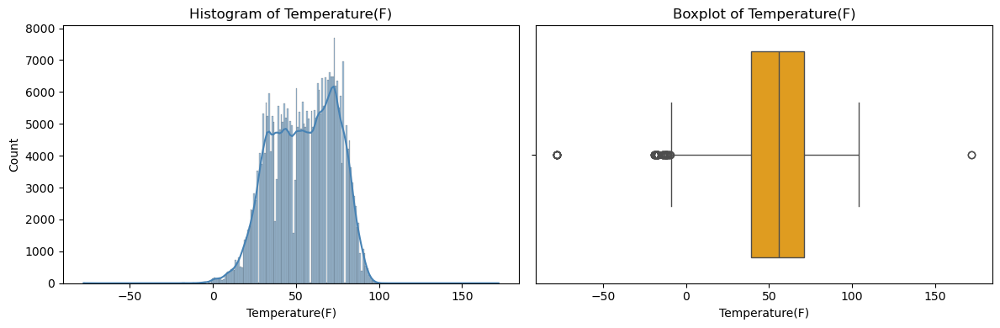

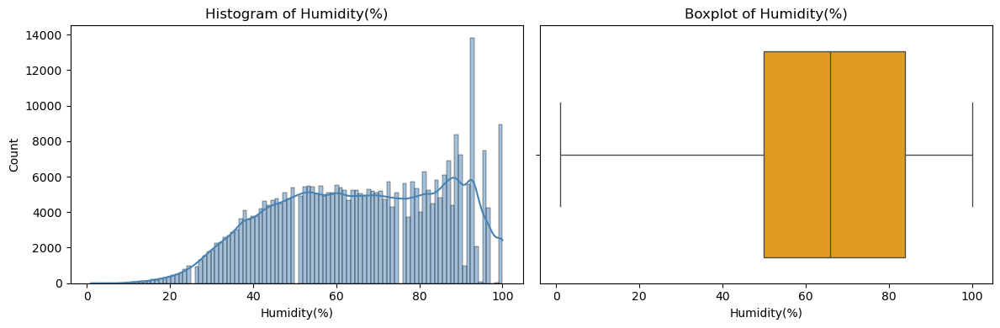

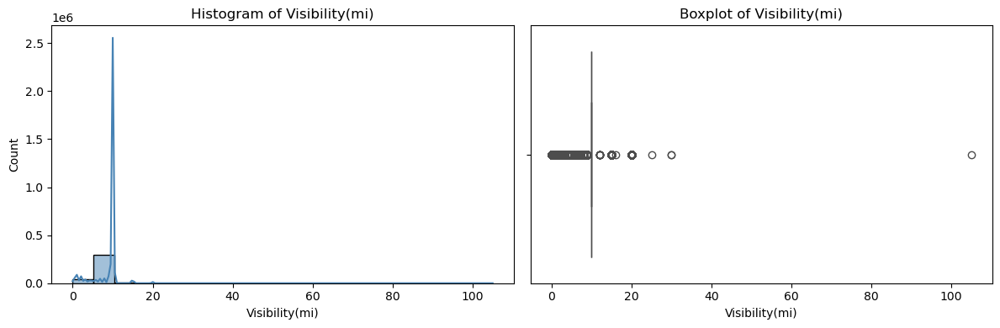

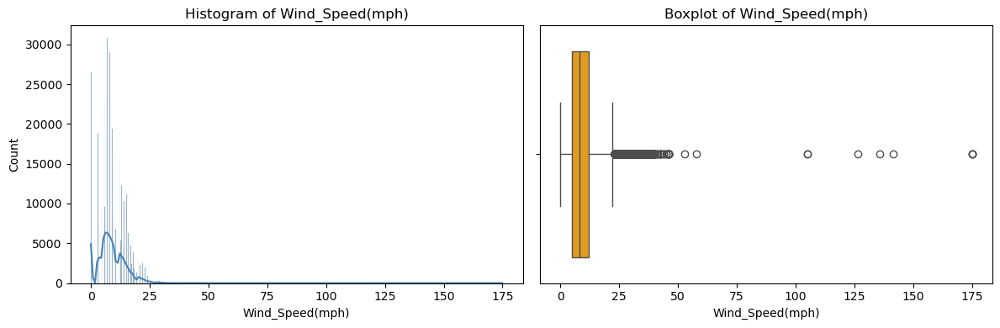

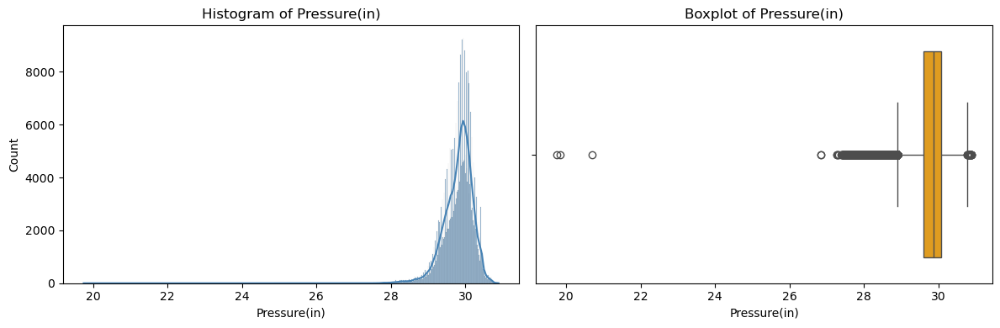

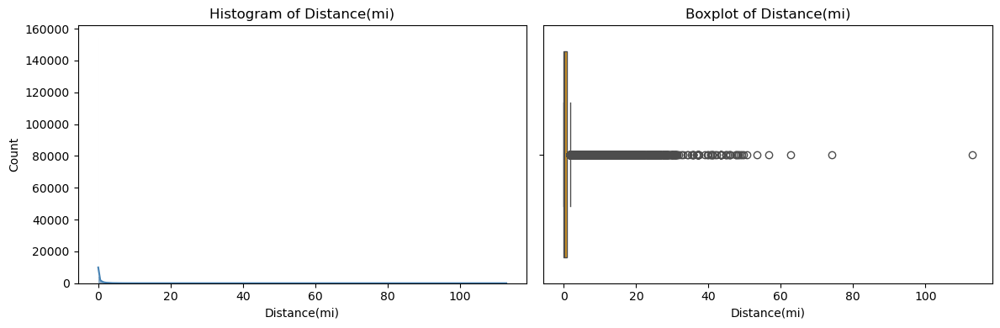

In [21]:
# 4 Numeric Features: Histograms and Boxplots
numeric_cols = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Pressure(in)','Distance(mi)']

for col in numeric_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Histogram
    sns.histplot(data[col].dropna(), ax=axes[0], kde=True, color='steelblue')
    axes[0].set_title(f'Histogram of {col}')
    
    # Boxplot
    sns.boxplot(x=data[col].dropna(), ax=axes[1], color='orange')
    axes[1].set_title(f'Boxplot of {col}')
    
    plt.tight_layout()
    plt.show()

<u>Humidity (%)</u>

* Right-skewed with a mode near ~80%; most observations are high-humidity conditions.

* Many values clustered near upper range with some lower outliers 

<u>Temperature (F)</u>

* Approximately bell-shaped with median around 30–60°F , slight left skew and both lower and upper outliers.

<u> Visibility (mi)</u>

* Heavy mass at low values (notably around 10 mi) with long right tail of high-visibility outliers.

<u>Wind Speed (mph)</u>

* Strong right skew: most events at low wind speeds, rare extreme outliers up to very high values.

<u>Pressure (in)</u>

* Narrow distribution clustered near ~29 in with some lower and upper outliers.


<u>Distance (mi)</u>

* Extremely right-skewed: massive concentration at very small distances and a long tail up to ~100 mi.


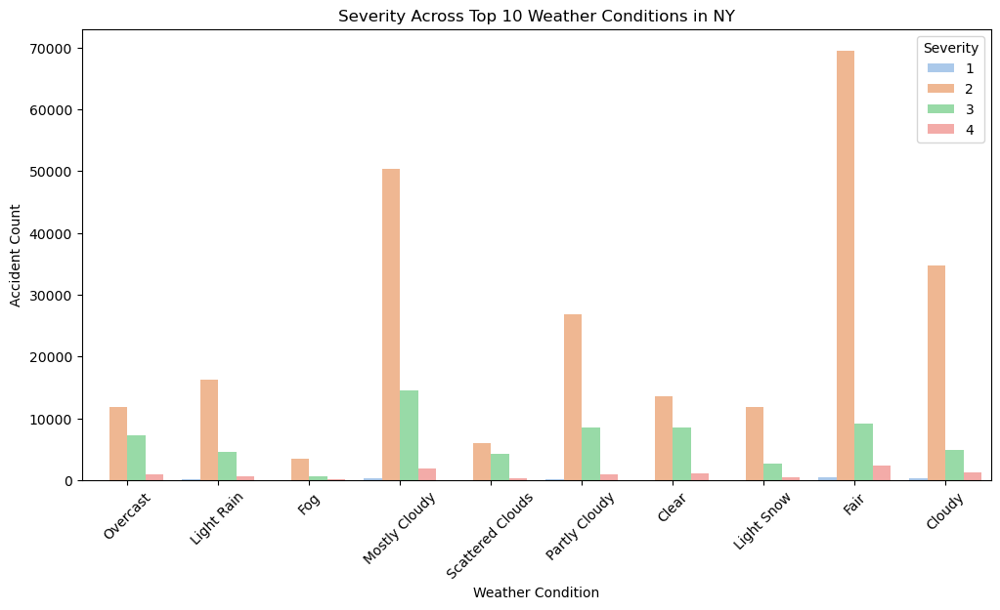

In [22]:
# 2 Severity vs Weather Conditions (Grouped Bar Chart)
top_weather = data['Weather_Condition'].value_counts().nlargest(10).index
df_weather = data[data['Weather_Condition'].isin(top_weather)]

plt.figure(figsize=(12, 6))
sns.countplot(data=df_weather, x='Weather_Condition', hue='Severity', palette='pastel')
plt.title('Severity Across Top 10 Weather Conditions in NY')
plt.xlabel('Weather Condition')
plt.ylabel('Accident Count')
plt.xticks(rotation=45)
plt.legend(title='Severity')
plt.show()

* Most accidents occur under fair/mostly cloudy/cloudy conditions, but lower-severity (1–2) dominates those categories while higher-severity (3–4) appears proportionally larger in adverse weather (fog, light rain, light snow).

In [23]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight', 'Severity_Class', 'Weekday', 'Month_Name',
       'Duration'],
      dtype='object')

In [24]:
data["Start_Time"].dt.hour

0         16
1         15
2         15
3         16
4         16
          ..
347955    16
347956    16
347957    16
347958    19
347959    17
Name: Start_Time, Length: 347960, dtype: int32

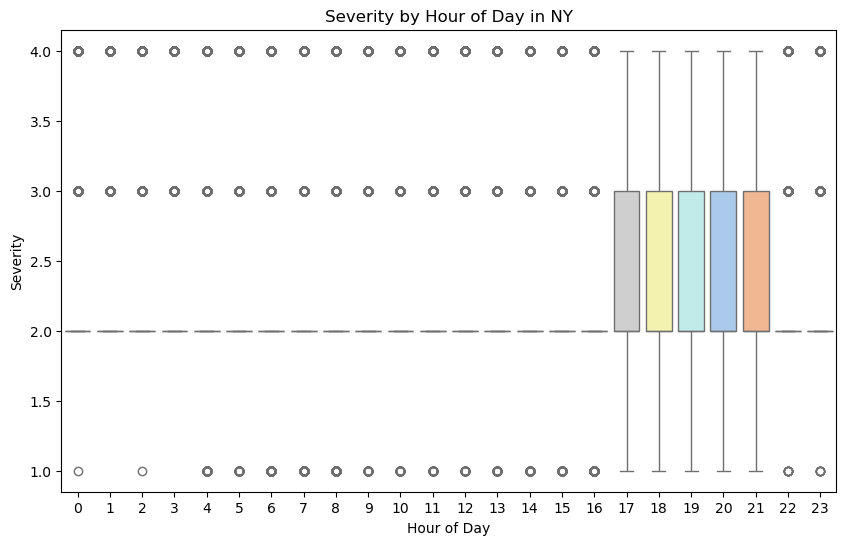

In [25]:
# 3 Severity vs Time of Day (Boxplot by Hour)
data['Hour'] = data['Start_Time'].dt.hour

plt.figure(figsize=(10, 6))
sns.boxplot(x='Hour', y='Severity', data=data, palette='pastel')
plt.title('Severity by Hour of Day in NY')
plt.xlabel('Hour of Day')
plt.ylabel('Severity')
plt.show()


* Median severity is higher and more variable during evening hours (roughly 17–22), matching the plot highlight.

* IQR and upper whiskers increase in the evening, indicating more frequent moderate-to-high severity crashes then.

* Overnight and mid-day hours show lower medians and tighter IQRs, implying most severe incidents cluster in late afternoon/evening.

* Many outliers across hours show a long right tail of rare high-severity events that will bias means.

In [26]:
data.columns

Index(['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat',
       'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description',
       'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone',
       'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction',
       'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity',
       'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway',
       'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal',
       'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight',
       'Astronomical_Twilight', 'Severity_Class', 'Weekday', 'Month_Name',
       'Duration', 'Hour'],
      dtype='object')

In [27]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347960 entries, 0 to 347959
Data columns (total 51 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   ID                     347960 non-null  object        
 1   Source                 347960 non-null  object        
 2   Severity               347960 non-null  int64         
 3   Start_Time             347960 non-null  datetime64[ns]
 4   End_Time               347960 non-null  datetime64[ns]
 5   Start_Lat              347960 non-null  float64       
 6   Start_Lng              347960 non-null  float64       
 7   End_Lat                194902 non-null  float64       
 8   End_Lng                194902 non-null  float64       
 9   Distance(mi)           347960 non-null  float64       
 10  Description            347959 non-null  object        
 11  Street                 347312 non-null  object        
 12  City                   347932 non-null  obje

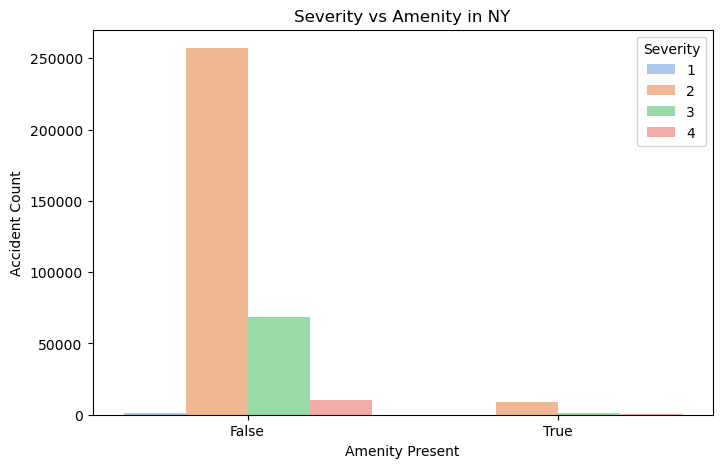

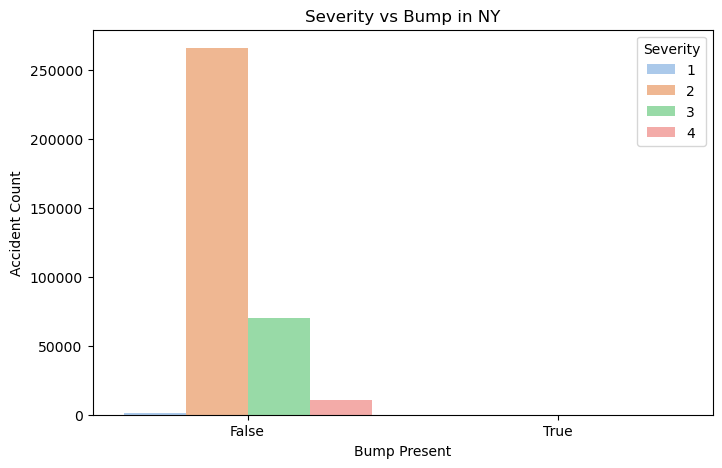

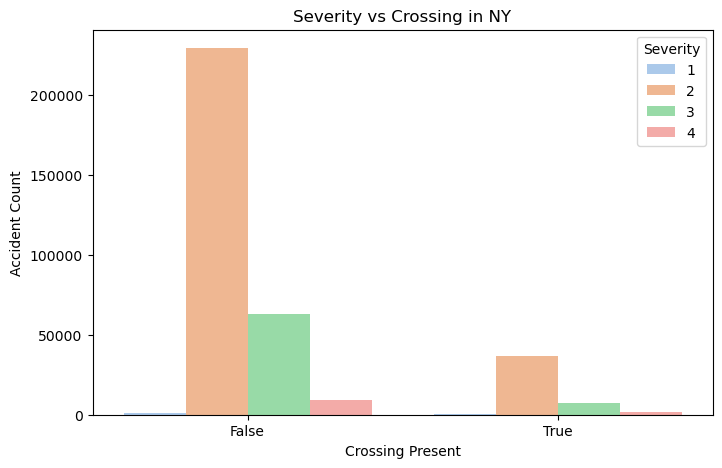

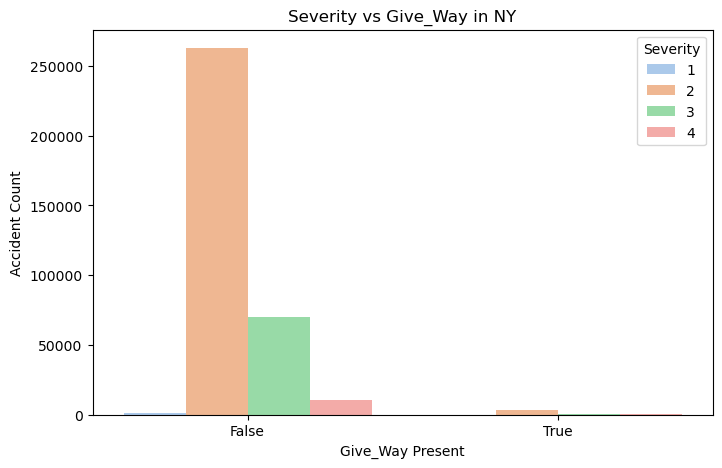

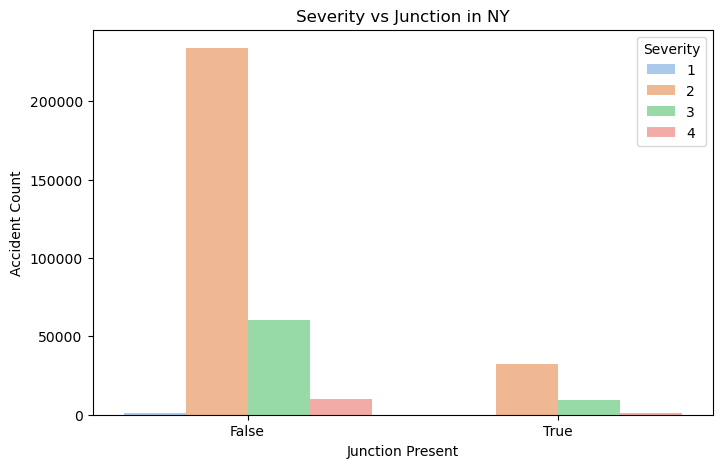

...

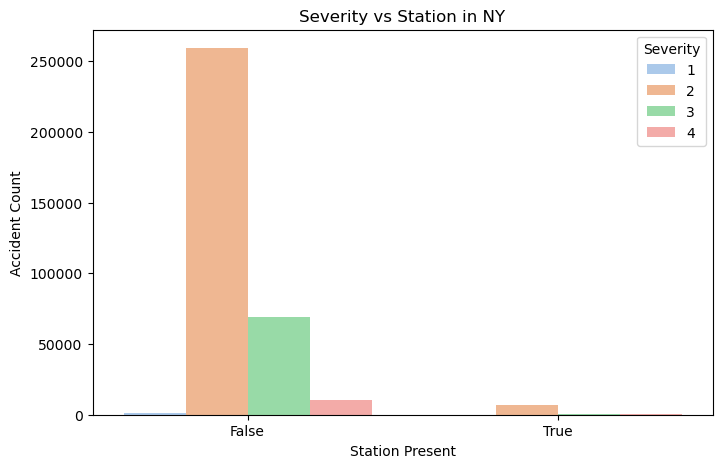

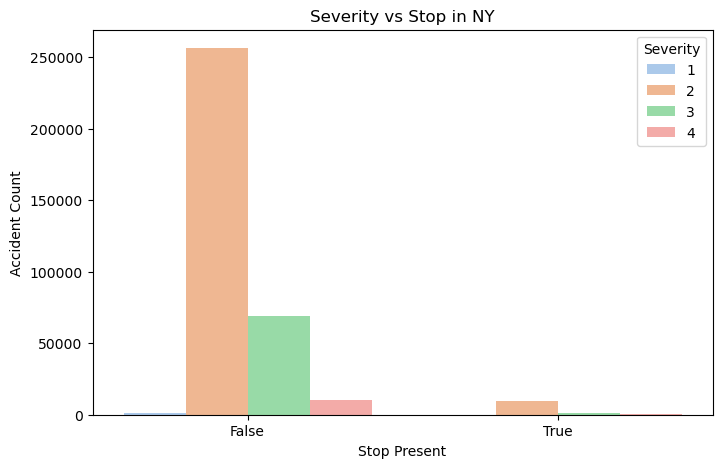

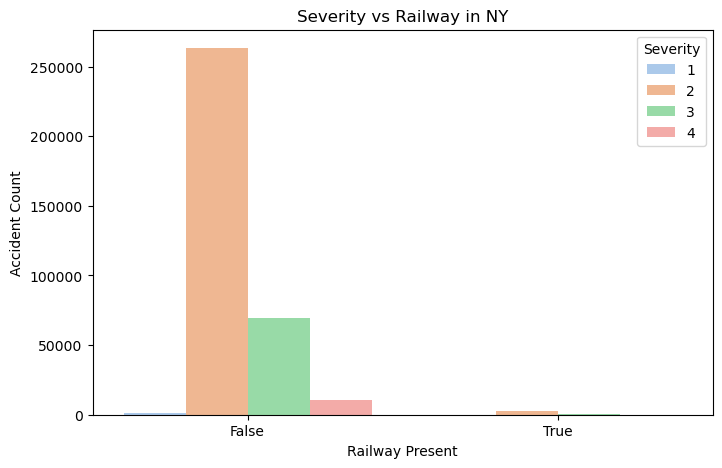

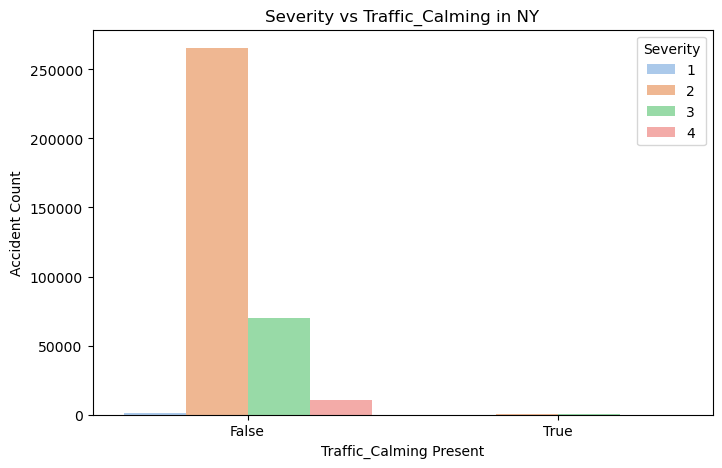

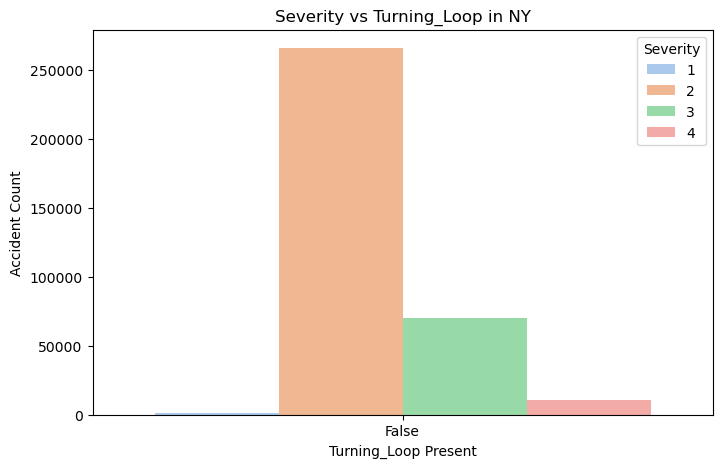

In [28]:
# 4 Severity vs Road Infrastructure Features
# Select relevant infrastructure features
infra_features = ['Amenity','Bump','Crossing','Give_Way', 'Junction','No_Exit', 'Traffic_Signal', 'Roundabout','Station', 'Stop', 'Railway','Traffic_Calming','Turning_Loop']

for feature in infra_features:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=data, x=feature, hue='Severity', palette='pastel')
    plt.title(f'Severity vs {feature} in NY')
    plt.xlabel(f'{feature} Present')
    plt.ylabel('Accident Count')
    plt.legend(title='Severity')
    plt.show()

<u>Infrastructure features vs severity </u>

Overall pattern: locations without built features (amenity, bump, crossing, give_way, junction, exit, traffic_signal, roundabout, station, stop, railway, traffic_calming) account for the vast majority of accidents. Severity‑2 is the single largest class across almost all features.

Protective features: presence of traffic controls and calming (traffic_signal, roundabout, stop, give_way, traffic_calming) is associated with markedly lower accident counts across all severities - suggests these features reduce exposure or mitigate crash frequency.

Traffic calming signal: sites with traffic calming, roundabouts, or signals show the greatest absolute reduction in counts, supporting their value for harm reduction.

Crossing / station / railway: locations with crossings, stations, or railways show fewer crashes overall but may concentrate specific vulnerability types (pedestrian or rail-adjacent incidents) - investigate rate per exposure.

Bump / turning loop / no_exit: very few accidents occur where bumps or turning loops exist. These features may indicate low-speed, controlled environments with lower severity.

### Multivariate analysis:

 * Correlation heatmap of numeric features.
 * Pivot tables/heatmaps (e.g. hour × day of week).
 * Combined effects of weather + time on severity.

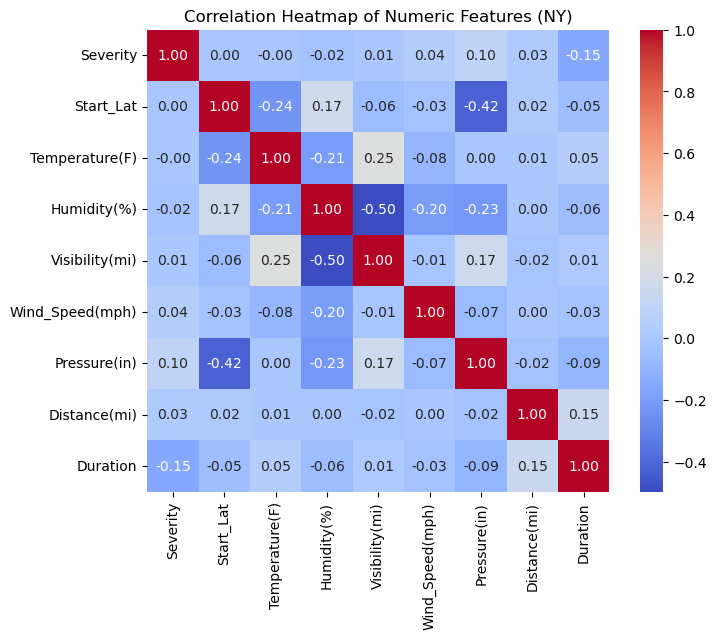

In [32]:
# 1 Correlation Heatmap of Numeric Features
# numeric_cols = ['Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Pressure(in)','Distance(mi)']
numeric_cols = ['Severity','Start_Lat', 'Temperature(F)', 'Humidity(%)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Pressure(in)','Distance(mi)','Duration']
# numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = data[numeric_cols].dropna().corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Correlation Heatmap of Numeric Features (NY)')
plt.show()

Severity shows only very weak correlations with the plotted numeric features (no |r| near 1), so linear relationships alone won’t explain much variance in severity.

Temperature vs Humidity has a weak negative correlation (r is around -0.21), indicating cooler observations tend to be slightly more humid.

Visibility, wind, pressure, distance and latitude show only small pairwise correlations with each other and with severity, suggesting orthogonal signals or nonlinear relationships.


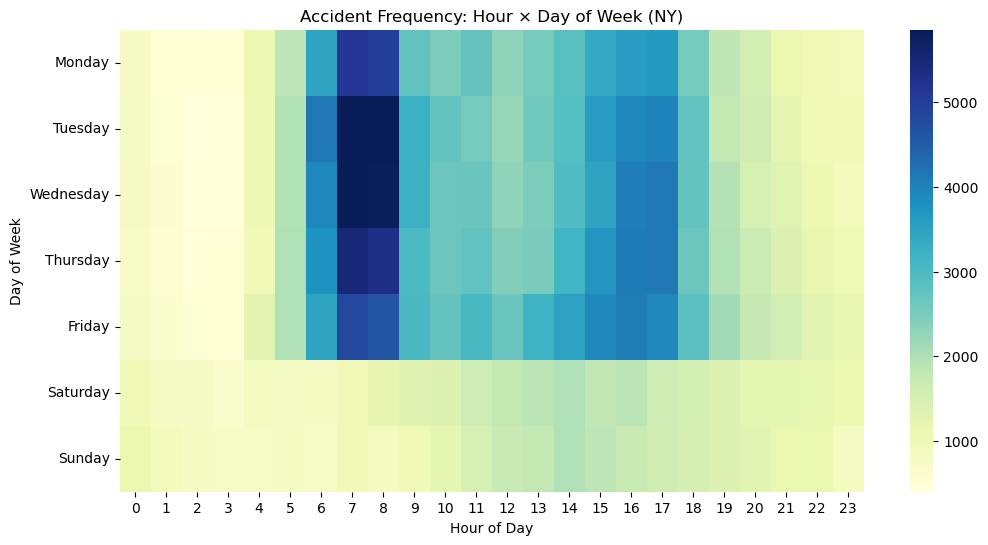

In [30]:
# 2 Pivot Table / Heatmap: Hour × Day of Week
data['Hour'] = data['Start_Time'].dt.hour
data['Weekday'] = data['Start_Time'].dt.dayofweek.map(lambda x: calendar.day_name[x])

pivot_table = data.pivot_table(index='Weekday', columns='Hour', values='ID', aggfunc='count').fillna(0)
pivot_table = pivot_table.reindex(index=list(calendar.day_name))  # Ensure correct weekday order
pivot_table
plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap='YlGnBu')
plt.title('Accident Frequency: Hour × Day of Week (NY)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

* Strong weekday commute peaks: highest counts Mon–Fri around 06–09 and 15–18.

* Weekends show uniformly lower frequencies, especially overnight.

* Monday mornings slightly elevated versus other weekdays.

* Morning peak is sharper, afternoon/evening peak is broader and extends later.

* Operational focus: prioritize staffing, enforcement, and messaging during weekday commute windows.

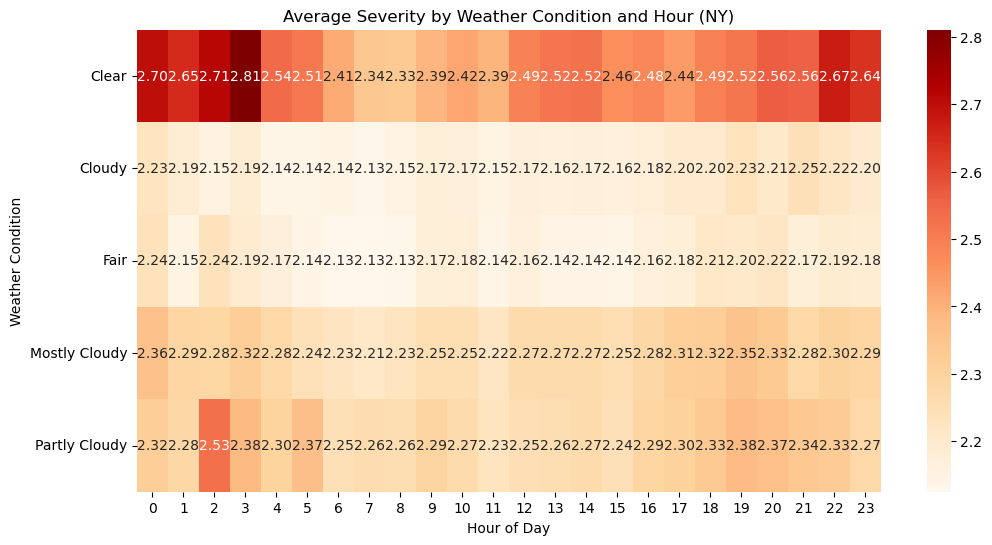

In [31]:
# 3 Combined Effects: Weather + Hour on Severity
# Focus on top 5 weather conditions for clarity
top_weather = data['Weather_Condition'].value_counts().nlargest(5).index
df_combo = data[data['Weather_Condition'].isin(top_weather)]

# Group and average severity
grouped = df_combo.groupby(['Weather_Condition', 'Hour'])['Severity'].mean().unstack()

plt.figure(figsize=(12, 6))
sns.heatmap(grouped, cmap='OrRd', annot=True, fmt=".2f")
plt.title('Average Severity by Weather Condition and Hour (NY)')
plt.xlabel('Hour of Day')
plt.ylabel('Weather Condition')
plt.show()

* Clear conditions show the highest average severity, especially overnight and early morning hours.

* Severity tends to be higher during low-traffic hours (late night / early morning) for several weather types, suggesting crashes then are likelier to be serious.

* Daytime (midday) averages are generally lower, with Clear and Fair dropping toward the 2.4–2.5 range.

* Cloudy and Mostly Cloudy produce moderate severity values, typically below Clear’s peak but above the lowest cells.

* Hourly variation exists across weather types but the range is modest (2.1–2.8), so differences are meaningful but not extreme.